# Formative 1: Building a Pipeline for Time Series Data
## Task 1A: Understanding the Dataset & Task 1B: Analytical Questions

**Dataset:** Electricity Consumption and Production  
**Main target variable:** `Consumption`  
**Time column:** `DateTime`

This notebook documents dataset understanding, data-quality assessment, visual exploration, and analytical questions. The original CSV is kept unchanged as the raw source. A separate, reproducible preprocessing section at the end prepares a derived hourly dataset for downstream modelling; its assumptions are documented and should be shared with the group before the model pipeline is finalized.

**Important:** Unusual values are investigated rather than automatically labelled as errors. All plots and statistics should be regenerated by running the notebook from top to bottom.

## 1. Problem definition and dataset justification

Electricity demand changes over time. Understanding its temporal patterns can help describe periods of high and low demand and provide a foundation for forecasting future consumption.

In this notebook, we will explore historical electricity consumption alongside total production and generation-source measurements. The proposed forecasting target for the group's later modeling task is **`Consumption`**.

### Why this dataset is suitable
- It contains a timestamp column (`DateTime`) and a numerical target (`Consumption`).
- It includes additional measurements such as `Production`, `Wind`, `Solar`, `Coal`, and `Hydroelectric`.
- The time series can be explored using trends, time-of-day patterns, lagged values, and moving averages.
- Timestamped records can later be stored in a relational database and a document database and served through an API.

### Dataset source
Kaggle: [Electricity dataset](https://www.kaggle.com/datasets/mayuringle8890/electricity)


## 2. Learning objectives

By the end of this notebook, we should be able to:
1. Describe the dataset's size, columns, time range, and observation frequency.
2. Assess missing values, exact duplicate rows, repeated timestamps, negative values, and unusual numerical observations.
3. Describe numerical distributions using typical values, variability, skewness, and unusual observations.
4. Answer at least five analytical questions using visualizations and interpretations.
5. Include at least two time-series questions involving lagged features and moving averages.
6. Document a separate, reproducible preprocessing approach for downstream modelling without overwriting the raw dataset.

## 3. Import libraries

We use **pandas** for data handling, **NumPy** for numerical operations, and **Matplotlib** for visualizations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.



## 4. Load the Dataset from Google Drive

The dataset is stored in Google Drive so it can be accessed
whenever the notebook is reopened. We mount Google Drive
and read the CSV directly from its project folder.

In [2]:
from google.colab import drive
import pandas as pd
from pathlib import Path

# Connect Google Drive to Colab
drive.mount('/content/drive')

# Path to the dataset stored in Google Drive
# Note: After mounting, the root of your Google Drive is under /content/drive/MyDrive/
DATA_PATH = Path(
    "/content/drive/MyDrive/TimeSeries_Project/Electricity.csv"
)

# Check that the file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Check the folder and filename in Google Drive."
    )

# Load the dataset
df_raw = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df_raw.shape)
display(df_raw.head())

Mounted at /content/drive
Dataset loaded successfully!
Shape: (46011, 10)


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
0,2019-01-01 00:00:00,6352,6527,1395,79,1383,1896,1744,0,30
1,2019-01-01 01:00:00,6116,5701,1393,96,1112,1429,1641,0,30
2,2019-01-01 02:00:00,5873,5676,1393,142,1030,1465,1616,0,30
3,2019-01-01 03:00:00,5682,5603,1397,191,972,1455,1558,0,30
4,2019-01-01 04:00:00,5557,5454,1393,159,960,1454,1458,0,30


## 5. Understand the dataset structure

This section checks the column names, data types, and a small sample of the records. The timestamp should be parsed as a datetime value before time-based analysis.

In [3]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types before conversion:")
print(df_raw.dtypes)

print("\nRandom sample of 5 rows:")
display(df_raw.sample(min(5, len(df_raw)), random_state=42))

Column names:
['DateTime', 'Consumption', 'Production', 'Nuclear', 'Wind', 'Hydroelectric', 'Oil and Gas', 'Coal', 'Solar', 'Biomass']

Data types before conversion:
DateTime         object
Consumption       int64
Production        int64
Nuclear           int64
Wind              int64
Hydroelectric     int64
Oil and Gas       int64
Coal              int64
Solar             int64
Biomass           int64
dtype: object

Random sample of 5 rows:


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
15854,2020-10-22 14:00:00,7009,6170,1384,515,2016,554,967,659,74
5159,2019-08-04 00:00:00,5558,6342,1344,1954,1033,375,1591,0,44
33445,2022-10-25 11:00:00,6791,6566,1377,169,2088,1327,1128,418,59
18729,2021-02-19 07:00:00,8808,8515,1400,618,3002,1828,1557,33,73
25018,2021-11-08 07:00:00,6736,5903,1412,65,1450,1517,1400,2,56


In [4]:
required_columns = {"DateTime", "Consumption"}
missing_required = required_columns - set(df_raw.columns)

if missing_required:
    raise ValueError(f"Required column(s) not found: {sorted(missing_required)}")

df = df_raw.copy()
df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")

invalid_timestamps = df["DateTime"].isna().sum()
print(f"Invalid or unparseable timestamps: {invalid_timestamps}")

if invalid_timestamps:
    display(df.loc[df["DateTime"].isna()].head())

# Remove rows that have no usable timestamp, since time-series analysis requires one.
df = df.dropna(subset=["DateTime"]).copy()
df = df.sort_values("DateTime").reset_index(drop=True)

print("\nData types after timestamp conversion:")
print(df.dtypes)

Invalid or unparseable timestamps: 0

Data types after timestamp conversion:
DateTime         datetime64[ns]
Consumption               int64
Production                int64
Nuclear                   int64
Wind                      int64
Hydroelectric             int64
Oil and Gas               int64
Coal                      int64
Solar                     int64
Biomass                   int64
dtype: object


## 6. Time range and observation frequency

We calculate the earliest and latest timestamps, the number of unique timestamps, and the gaps between consecutive unique timestamps.

**Important limitation:** the `DateTime` column may not include a timezone. If it represents local time, daylight-saving-time transitions can create repeated or skipped clock times. We will report what the file shows and investigate timestamp duplicates rather than assuming that every repeated timestamp is an error.

In [5]:
start_time = df["DateTime"].min()
end_time = df["DateTime"].max()
unique_times = pd.DatetimeIndex(df["DateTime"].drop_duplicates().sort_values())
time_diffs = unique_times.to_series().diff().dropna()

print(f"Start timestamp: {start_time}")
print(f"End timestamp:   {end_time}")
print(f"Calendar span:   {end_time - start_time}")
print(f"Rows with valid timestamps: {len(df):,}")
print(f"Unique timestamps: {df['DateTime'].nunique():,}")

print("\nMost common differences between unique timestamps:")
display(time_diffs.value_counts().head(10).rename_axis("Time difference").to_frame("Count"))

if not time_diffs.empty:
    print(f"Median interval between unique timestamps: {time_diffs.median()}")

Start timestamp: 2019-01-01 00:00:00
End timestamp:   2024-03-31 23:00:00
Calendar span:   1916 days 23:00:00
Rows with valid timestamps: 46,011
Unique timestamps: 46,002

Most common differences between unique timestamps:


,Count
Time difference,
0 days 01:00:00,45995
0 days 02:00:00,6


Median interval between unique timestamps: 0 days 01:00:00


## 7. Data-quality assessment

We check:
- missing values in each column;
- exact duplicate rows;
- repeated timestamps;
- numeric columns and their ranges;
- negative values in columns where negative measurements may be unexpected.

We will **not** automatically replace all unusual values or delete all repeated timestamps. First we measure the issue, then decide whether a transformation is justified and document it.

In [6]:
missing_summary = (
    df.isna().sum()
      .rename("missing_count")
      .to_frame()
)
missing_summary["missing_percent"] = 100 * missing_summary["missing_count"] / len(df)
display(missing_summary)

exact_duplicate_count = int(df.duplicated().sum())
duplicate_timestamp_count = int(df["DateTime"].duplicated(keep=False).sum())
repeated_timestamp_excess = int(df["DateTime"].duplicated().sum())

print(f"Exact duplicate rows (beyond the first copy): {exact_duplicate_count}")
print(f"Rows belonging to a repeated timestamp group: {duplicate_timestamp_count}")
print(f"Extra rows caused by repeated timestamps: {repeated_timestamp_excess}")

print("\nExamples of repeated timestamps:")
display(
    df.loc[df["DateTime"].duplicated(keep=False)]
      .sort_values("DateTime")
      .head(20)
)

,missing_count,missing_percent
DateTime,0,0.00
Consumption,0,0.00
Production,0,0.00
Nuclear,0,0.00
Wind,0,0.00
Hydroelectric,0,0.00
Oil and Gas,0,0.00
Coal,0,0.00
Solar,0,0.00
Biomass,0,0.00


Exact duplicate rows (beyond the first copy): 4
Rows belonging to a repeated timestamp group: 14
Extra rows caused by repeated timestamps: 9

Examples of repeated timestamps:


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
7178,2019-10-27 03:00:00,5186,4478,1373,77,750,696,1532,0,49
7179,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
7180,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
15915,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
15916,2020-10-25 03:00:00,5181,5356,1417,1120,1155,566,1034,0,65
15917,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
24820,2021-10-31 03:00:00,5351,5265,1414,108,961,1314,1411,0,56
24821,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
24822,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
33557,2022-10-30 03:00:00,4475,5266,1385,485,1375,904,1064,0,52


In [7]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
print("Numeric columns:", numeric_cols)

print("\nNegative-value counts by numeric column:")
negative_counts = (df[numeric_cols] < 0).sum().sort_values(ascending=False)
display(negative_counts.rename("negative_count").to_frame())

print("\nNumeric summary statistics:")
display(df[numeric_cols].describe().T)

Numeric columns: ['Consumption', 'Production', 'Nuclear', 'Wind', 'Hydroelectric', 'Oil and Gas', 'Coal', 'Solar', 'Biomass']

Negative-value counts by numeric column:


,negative_count
Wind,499
Consumption,0
Production,0
Nuclear,0
Hydroelectric,0
Oil and Gas,0
Coal,0
Solar,0
Biomass,0



Numeric summary statistics:


,count,mean,std,min,25%,50%,75%,max
Consumption,"46,011.00","6,587.62","1,043.65","3,889.00","5,773.00","6,552.00","7,321.00","9,615.00"
Production,"46,011.00","6,518.65",986.81,"3,315.00","5,814.00","6,462.00","7,176.00","9,886.00"
Nuclear,"46,011.00","1,291.18",236.55,562.00,"1,347.00","1,383.00","1,405.00","1,457.00"
Wind,"46,011.00",792.31,675.81,-26.00,236.00,592.00,"1,205.00","2,811.00"
Hydroelectric,"46,011.00","1,857.05",692.59,175.00,"1,347.00","1,747.00","2,265.00","4,434.00"
Oil and Gas,"46,011.00","1,171.89",434.75,198.00,858.00,"1,211.00","1,511.00","2,141.00"
Coal,"46,011.00","1,193.16",320.45,279.00,962.00,"1,172.00","1,406.00","2,537.00"
Solar,"46,011.00",156.69,229.50,0.00,0.00,2.00,280.00,"1,137.00"
Biomass,"46,011.00",55.85,14.24,17.00,45.00,57.00,67.00,89.00


### Data-quality findings and decisions

The checks above are an **assessment of the raw data**, not changes to the source CSV. Use the results to document the decisions below.

- **Missing cells:** report the actual counts. If none are present in the original CSV, state that no cell-level missing values were found before preprocessing.
- **Exact duplicate rows:** inspect them and remove only exact duplicates in the derived modelling dataset.
- **Repeated timestamps:** investigate them. In the derived hourly dataset below, remaining records with the same timestamp are combined by taking the mean of numeric columns; this is an explicit assumption and should be reported.
- **Negative generation values:** negative wind values are present. They are not silently clipped to zero. The modelling-preparation section treats negative generation readings as missing values and imputes only short internal gaps, which is an assumption that should be reviewed by the group.
- **Missing hourly timestamps:** the modelling-preparation section creates a regular hourly index and fills only short internal gaps. Longer gaps remain missing and rows with incomplete model features are excluded from the feature table.
- **Outliers:** boxplots flag unusual observations but do not prove that values are invalid. Keep plausible peaks unless further evidence supports changing them.

The original `Electricity.csv` file remains unchanged. All transformations below create a separate derived dataset.

## 8. Numerical distributions

The summary table describes central tendency and spread. Histograms show each variable's distribution, while boxplots help identify extreme values. Because variables may have very different scales, the boxplots are drawn separately.

,count,mean,std,min,25%,50%,75%,max
Consumption,"46,011.00","6,587.62","1,043.65","3,889.00","5,773.00","6,552.00","7,321.00","9,615.00"
Production,"46,011.00","6,518.65",986.81,"3,315.00","5,814.00","6,462.00","7,176.00","9,886.00"
Nuclear,"46,011.00","1,291.18",236.55,562.00,"1,347.00","1,383.00","1,405.00","1,457.00"
Wind,"46,011.00",792.31,675.81,-26.00,236.00,592.00,"1,205.00","2,811.00"
Hydroelectric,"46,011.00","1,857.05",692.59,175.00,"1,347.00","1,747.00","2,265.00","4,434.00"
Oil and Gas,"46,011.00","1,171.89",434.75,198.00,858.00,"1,211.00","1,511.00","2,141.00"
Coal,"46,011.00","1,193.16",320.45,279.00,962.00,"1,172.00","1,406.00","2,537.00"
Solar,"46,011.00",156.69,229.50,0.00,0.00,2.00,280.00,"1,137.00"
Biomass,"46,011.00",55.85,14.24,17.00,45.00,57.00,67.00,89.00


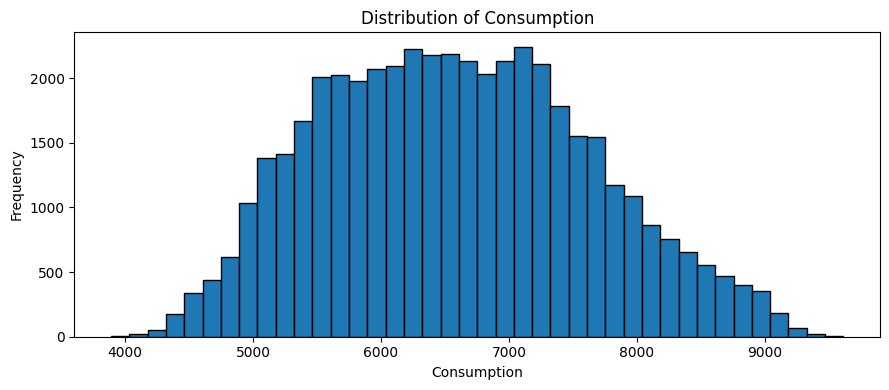

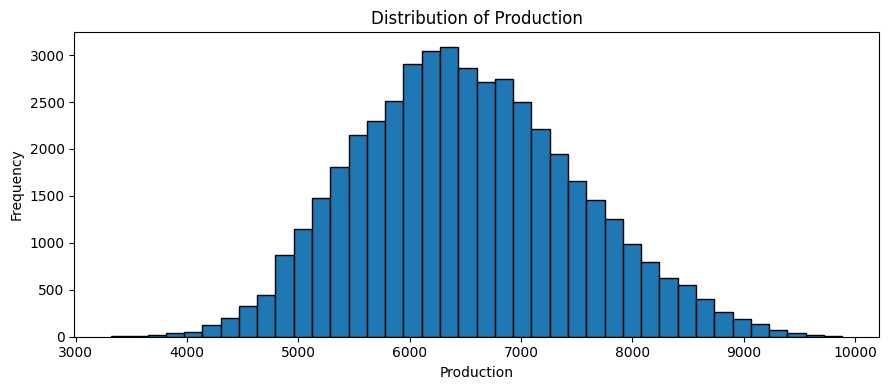

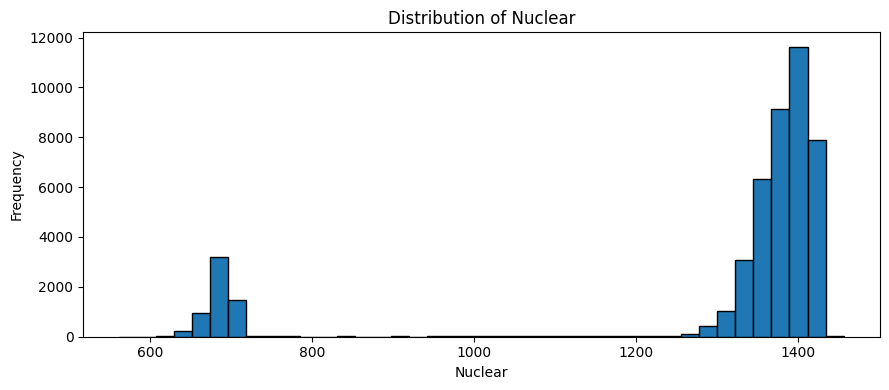

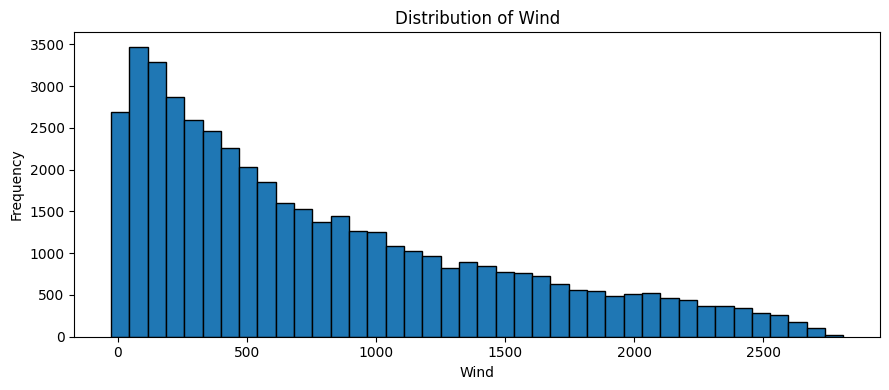

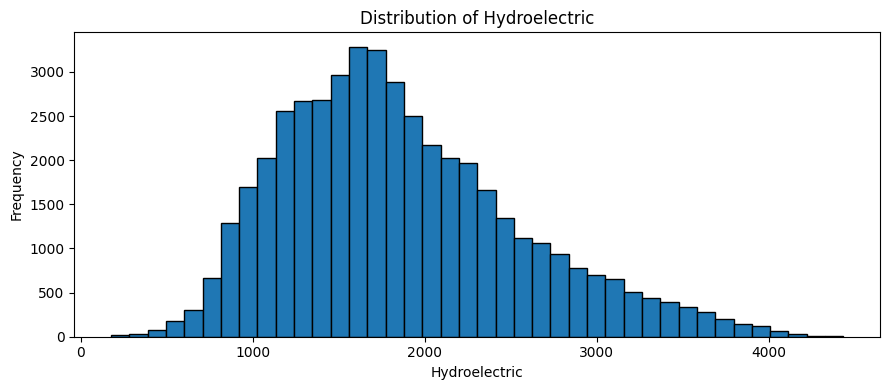

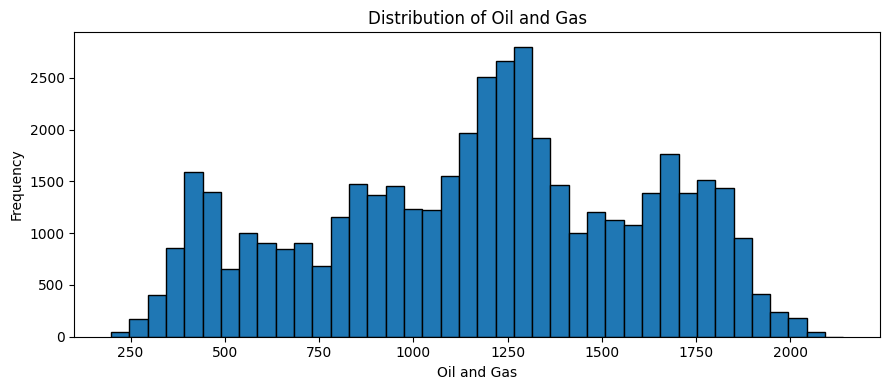

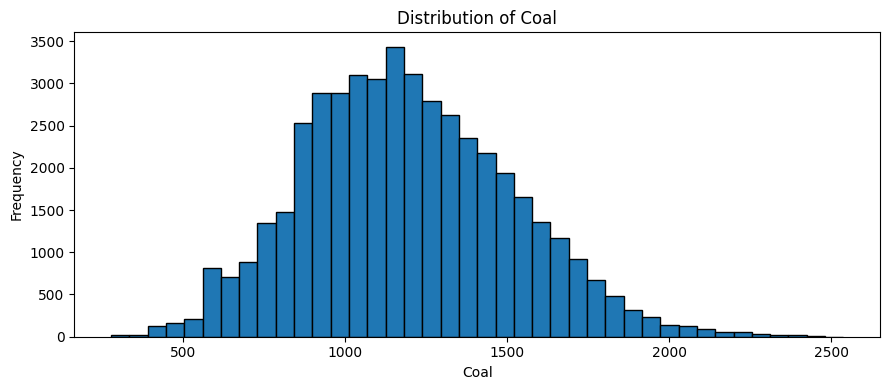

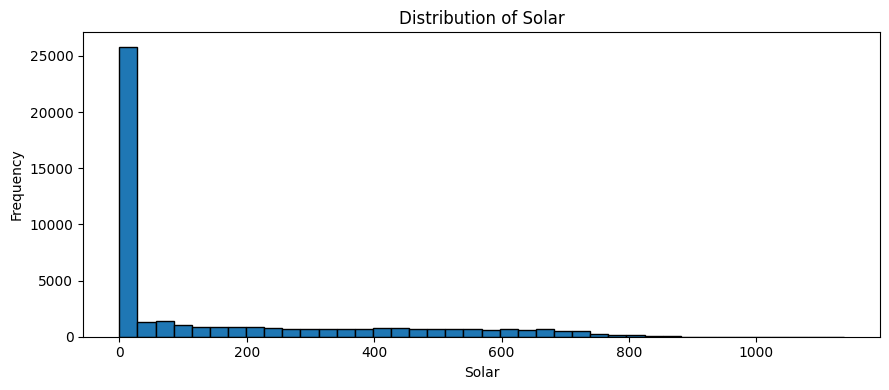

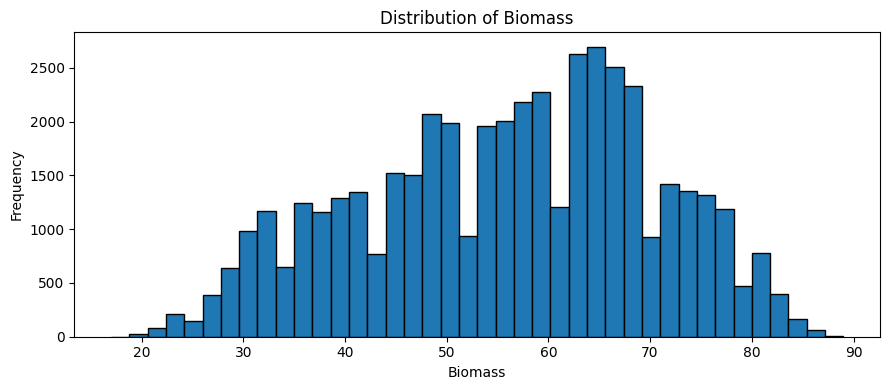

In [8]:
display(df[numeric_cols].describe().T)

for col in numeric_cols:
    plt.figure(figsize=(9, 4))
    plt.hist(df[col].dropna(), bins=40, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

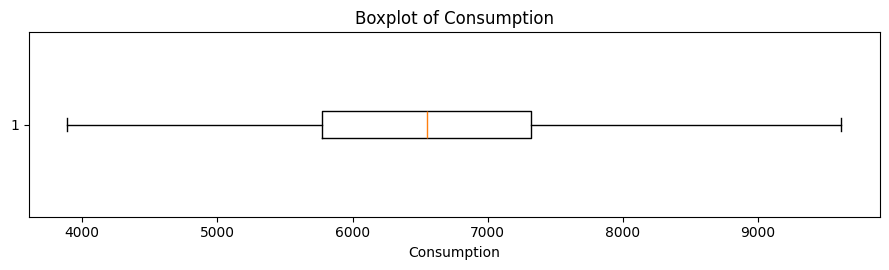

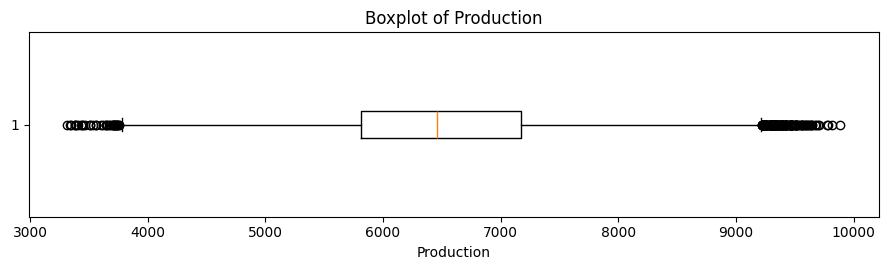

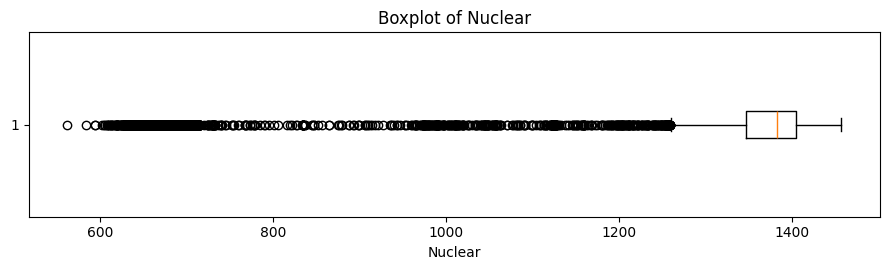

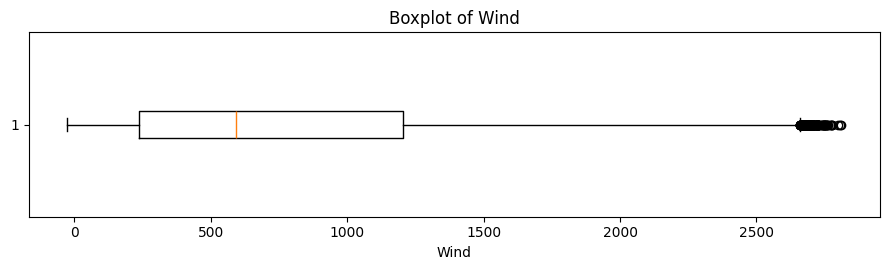

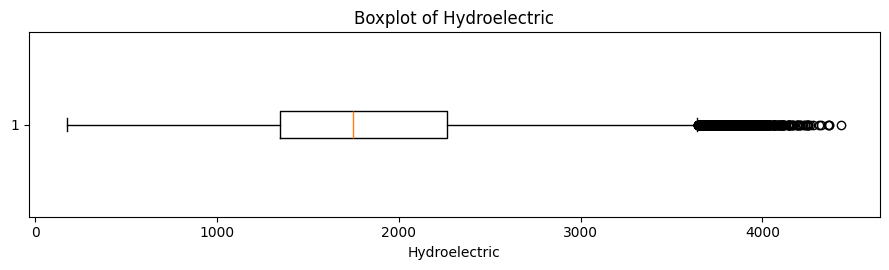

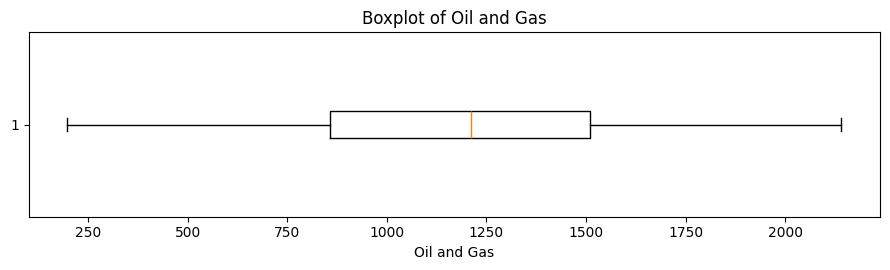

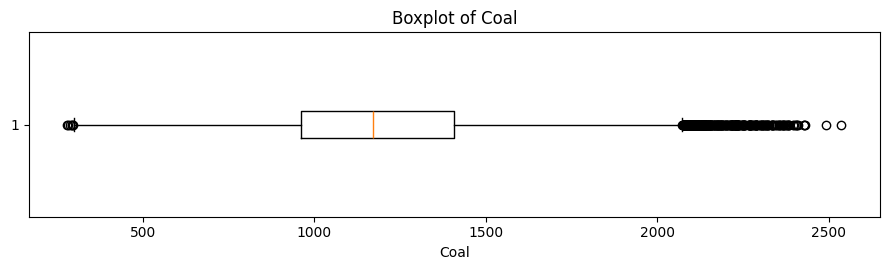

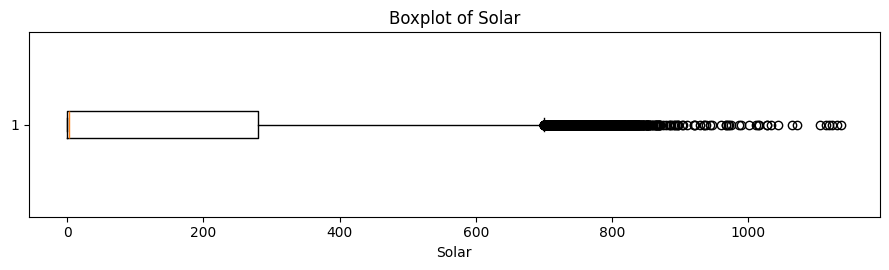

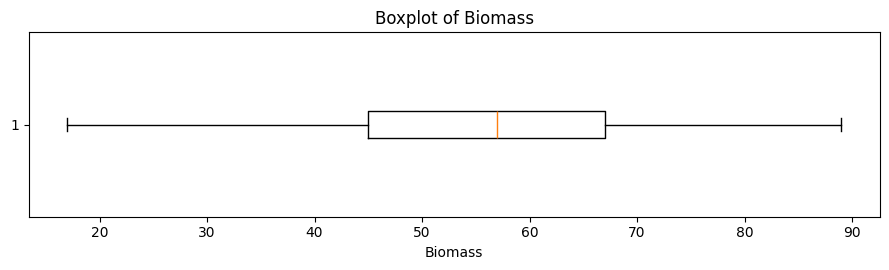

In [9]:
for col in numeric_cols:
    plt.figure(figsize=(9, 2.8))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

### Interpretation of Numerical Distributions

The numerical distributions show that electricity consumption and total production have similar typical values, with mean values of approximately 6,588 and 6,519, respectively. Their means are slightly higher than their medians, suggesting mildly right-skewed distributions. Both variables also show considerable variability, with standard deviations of approximately 1,044 for consumption and 987 for production.

Among the energy sources, nuclear and biomass generation appear more concentrated around their central values, while wind and hydroelectric generation show greater variability. Wind generation has a mean of approximately 792 and a median of 592, suggesting a right-skewed distribution with some periods of much higher output. Solar generation has a particularly noticeable pattern: its median is only 2, its first quartile is zero, and its mean is approximately 157. This suggests that many observations have very low or zero solar generation, while some periods have substantially higher output.

The boxplots also highlight observations that may be unusually high or low. For example, consumption ranges from 3,889 to 9,615, hydroelectric generation ranges from 175 to 4,434, and solar generation reaches 1,137. Wind generation also contains negative values, with a minimum of −26, which should be investigated to understand how these values were recorded. However, unusually high or low observations are not necessarily errors; they may represent genuine changes in electricity demand or generation.

Overall, the distributions reveal differences in the variability and behaviour of the electricity variables. These findings help identify patterns and observations that deserve further investigation before proceeding with additional time-series analysis. Any decisions to remove or modify unusual values should be based on further checks rather than the boxplots alone.

## 9. Overall electricity-consumption trend

### Analytical question 1
**How has electricity consumption changed over the recorded period?**

We plot the raw series and a daily mean series. The daily mean makes longer-term patterns easier to see without removing the underlying hourly variation from the dataset.

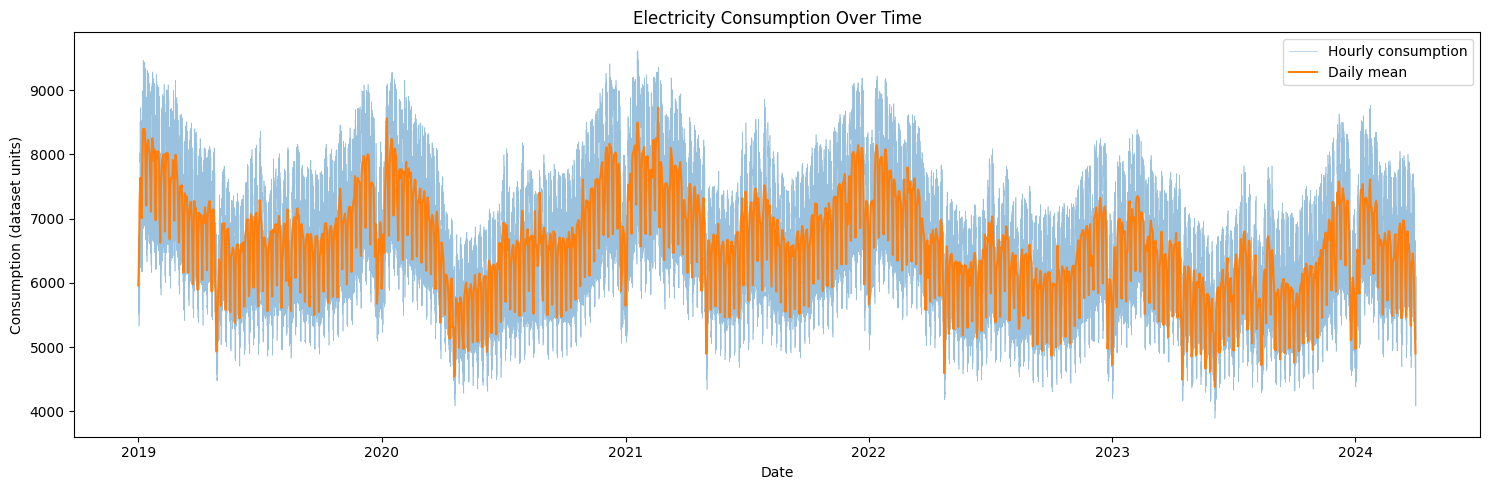

Consumption summary:


,count,mean,std,min,25%,50%,75%,max
Consumption,"46,011.00","6,587.62","1,043.65","3,889.00","5,773.00","6,552.00","7,321.00","9,615.00"


In [10]:
consumption_daily = (
    df.set_index("DateTime")["Consumption"]
      .resample("D")
      .mean()
)

plt.figure(figsize=(15, 5))
plt.plot(df["DateTime"], df["Consumption"], linewidth=0.45, alpha=0.45, label="Hourly consumption")
plt.plot(consumption_daily.index, consumption_daily.values, linewidth=1.5, label="Daily mean")
plt.title("Electricity Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Consumption (dataset units)")
plt.legend()
plt.tight_layout()
plt.show()

print("Consumption summary:")
display(df["Consumption"].describe().to_frame().T)

##Interpretation
The time-series visualization shows that electricity consumption fluctuates considerably throughout the recorded period from 2019 to 2024. The daily mean series makes the broader patterns easier to observe while reducing some of the short-term variation in the hourly data. Consumption shows recurring peaks and declines, with some of the highest levels occurring around 2019–2022. The graph also suggests that consumption levels are generally lower during parts of 2023 compared with earlier years, although fluctuations continue into 2024. Overall, electricity consumption is not constant over time, which supports the need to investigate temporal patterns when analysing and forecasting electricity demand.

## 10. Time-of-day pattern

### Analytical question 2
**At which hours of the day is average electricity consumption highest and lowest?**

This analysis groups observations by hour of the day. It can reveal a typical daily pattern, but it does not by itself establish why the pattern occurs.

,mean,median,std,count
hour,,,,
0,"5,862.20","5,839.00",548.74,1917
1,"5,653.46","5,622.00",547.62,1917
2,"5,536.32","5,504.00",552.52,1917
3,"5,484.18","5,445.50",558.09,1920
4,"5,515.10","5,472.00",570.67,1917
5,"5,626.23","5,579.00",618.18,1917
6,"5,949.99","5,885.00",741.45,1917
7,"6,511.37","6,494.00",909.00,1917
8,"6,940.53","6,964.00","1,002.69",1917


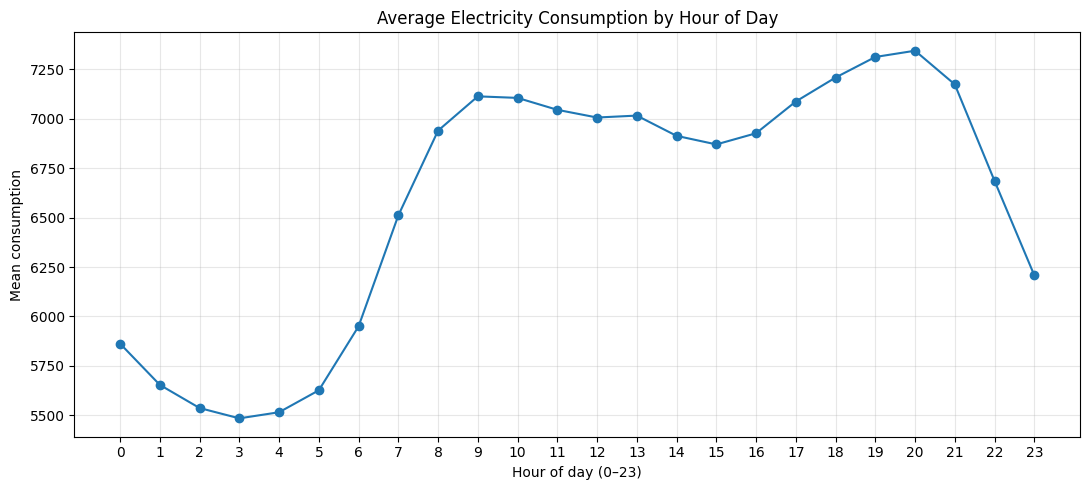

Highest average consumption hour: 20:00
Lowest average consumption hour:  03:00


In [11]:
df["hour"] = df["DateTime"].dt.hour
hourly_profile = df.groupby("hour")["Consumption"].agg(["mean", "median", "std", "count"])

display(hourly_profile)

plt.figure(figsize=(11, 5))
plt.plot(hourly_profile.index, hourly_profile["mean"], marker="o")
plt.xticks(range(0, 24))
plt.title("Average Electricity Consumption by Hour of Day")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Mean consumption")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

highest_hour = int(hourly_profile["mean"].idxmax())
lowest_hour = int(hourly_profile["mean"].idxmin())
print(f"Highest average consumption hour: {highest_hour:02d}:00")
print(f"Lowest average consumption hour:  {lowest_hour:02d}:00")

##Interpretation

The results show a clear daily pattern in electricity consumption. Average consumption is lowest at **03:00**, at approximately 5,484 units, and highest at **20:00**, at approximately 7,345 units. Consumption gradually decreases during the early morning, reaching its lowest level around 03:00, before rising sharply from 06:00 to 09:00. It remains relatively high throughout much of the day, with another increase during the evening and a peak at 20:00. After 21:00, consumption begins to decline. This pattern suggests that electricity demand varies according to the time of day, making the hour an important feature for further time-series analysis. However, the visualization alone does not establish the reasons for these changes.

## 11. Lag analysis

### Analytical question 3: Required lagged-feature question
**How strongly is current electricity consumption associated with consumption one hour earlier?**

A lag feature shifts the target so each row contains a previous observation. `Consumption_lag_1` is the prior recorded observation after sorting by timestamp. Because the file contains repeated timestamps, interpret this as the **previous row in time-sorted data**, not as a guaranteed distinct clock hour. We also show how much the lagged correlation is affected by the data structure.

Correlation between consumption and previous-row consumption: 0.9621


,Consumption,Consumption_lag_1
count,"46,010.00","46,010.00"
mean,"6,587.62","6,587.65"
std,"1,043.67","1,043.64"
min,"3,889.00","3,889.00"
25%,"5,773.00","5,773.00"
50%,"6,552.00","6,552.00"
75%,"7,321.00","7,321.00"
max,"9,615.00","9,615.00"


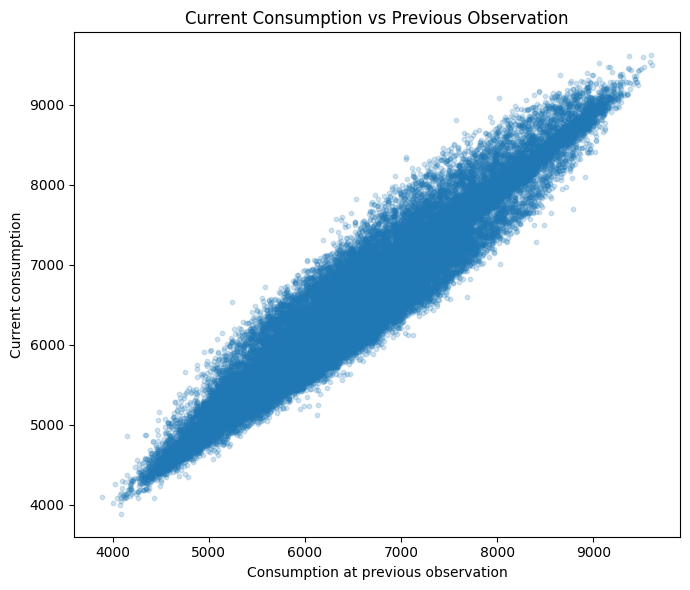

In [12]:
lag_df = df[["DateTime", "Consumption"]].copy()
lag_df = lag_df.sort_values("DateTime").reset_index(drop=True)
lag_df["Consumption_lag_1"] = lag_df["Consumption"].shift(1)
lag_pairs = lag_df.dropna(subset=["Consumption", "Consumption_lag_1"]).copy()

lag_corr = lag_pairs["Consumption"].corr(lag_pairs["Consumption_lag_1"])
print(f"Correlation between consumption and previous-row consumption: {lag_corr:.4f}")
display(lag_pairs[["Consumption", "Consumption_lag_1"]].describe())

plt.figure(figsize=(7, 6))
plt.scatter(lag_pairs["Consumption_lag_1"], lag_pairs["Consumption"], alpha=0.2, s=10)
plt.title("Current Consumption vs Previous Observation")
plt.xlabel("Consumption at previous observation")
plt.ylabel("Current consumption")
plt.tight_layout()
plt.show()

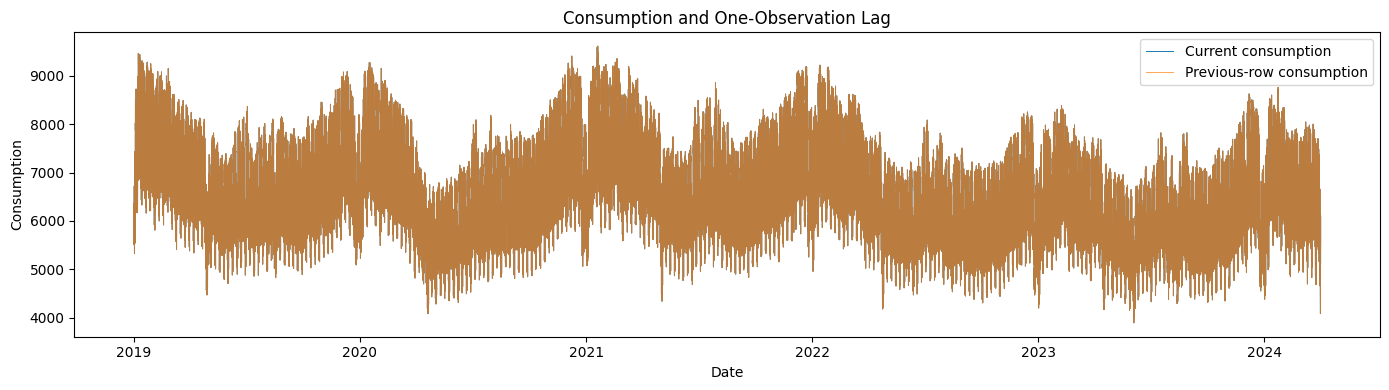

In [13]:
plt.figure(figsize=(14, 4))
plt.plot(lag_df["DateTime"], lag_df["Consumption"], label="Current consumption", linewidth=0.7)
plt.plot(lag_df["DateTime"], lag_df["Consumption_lag_1"], label="Previous-row consumption", linewidth=0.7, alpha=0.7)
plt.title("Consumption and One-Observation Lag")
plt.xlabel("Date")
plt.ylabel("Consumption")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

The correlation between current consumption and the previous recorded observation is **0.9621**, indicating a very strong positive linear relationship. The scatter plot shows an upward-sloping pattern: higher consumption in the previous observation is generally associated with higher current consumption. This suggests that electricity consumption has strong temporal continuity and that recent consumption may be useful for forecasting. Because the raw dataset contains repeated timestamps, this exploratory lag is based on the previous recorded row and is not guaranteed to represent exactly one elapsed hour. The correlation also does not establish causation or guarantee forecasting performance.

## 12. Moving-average analysis

### Analytical question 4: Required moving-average question
**How does a rolling 24-observation average help reveal changes in electricity consumption?**

A moving average smooths short-term fluctuations. Since the timestamps include repeated clock times and may include gaps, this feature is calculated over **24 consecutive observations**, rather than claiming every window always represents exactly 24 elapsed hours. The rolling window uses current and previous observations; it does not use future values.

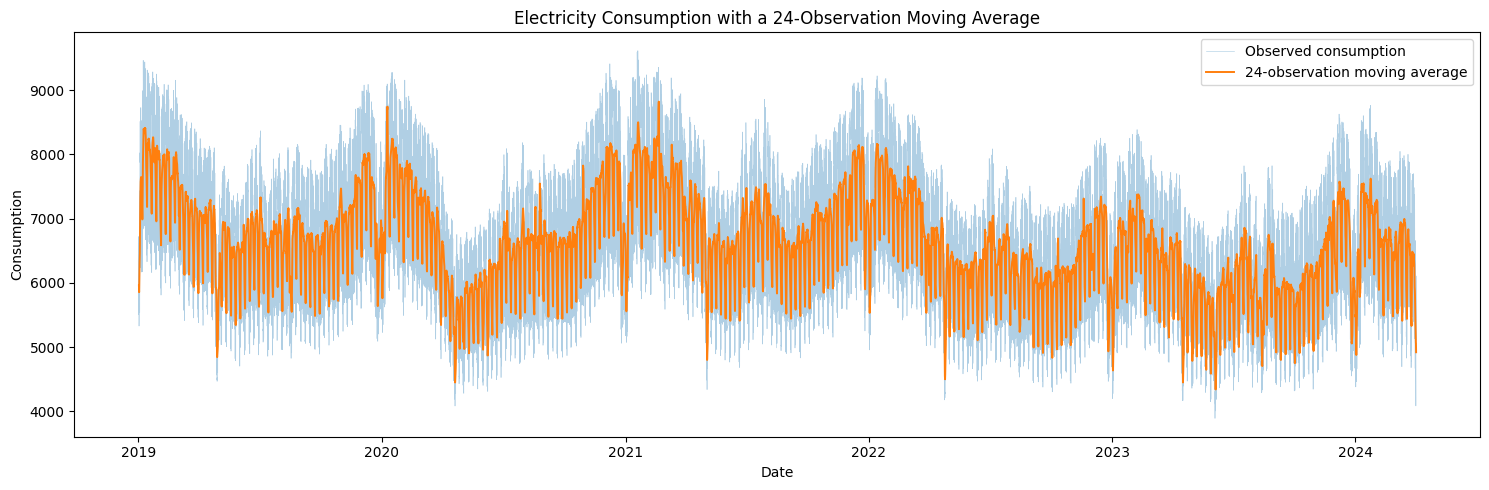

,Consumption,Consumption_MA_24obs
count,"46,011.00","45,988.00"
mean,"6,587.62","6,588.19"
std,"1,043.65",744.47
min,"3,889.00","4,339.42"
25%,"5,773.00","6,062.35"
50%,"6,552.00","6,601.08"
75%,"7,321.00","7,083.72"
max,"9,615.00","8,821.75"


In [15]:
ma_df = df[["DateTime", "Consumption"]].copy()
ma_df = ma_df.sort_values("DateTime").reset_index(drop=True)
ma_df["Consumption_MA_24obs"] = ma_df["Consumption"].rolling(window=24, min_periods=24).mean()

plt.figure(figsize=(15, 5))
plt.plot(ma_df["DateTime"], ma_df["Consumption"], linewidth=0.45, alpha=0.35, label="Observed consumption")
plt.plot(ma_df["DateTime"], ma_df["Consumption_MA_24obs"], linewidth=1.4, label="24-observation moving average")
plt.title("Electricity Consumption with a 24-Observation Moving Average")
plt.xlabel("Date")
plt.ylabel("Consumption")
plt.legend()
plt.tight_layout()
plt.show()

display(ma_df[["Consumption", "Consumption_MA_24obs"]].describe())

### Interpretation

The 24-observation moving average smooths short-term fluctuations and makes broader changes in consumption easier to see. Its standard deviation is lower than that of the original consumption series, and its maximum and minimum are less extreme because each average combines multiple observations. The overall mean remains similar, while individual peaks and dips are softened. Since this calculation uses 24 consecutive rows from the sorted data, it is a 24-observation moving average; repeated timestamps mean it is not guaranteed to cover exactly 24 elapsed hours.

## 13. Relationship between production and consumption

### Analytical question 5
**How does reported electricity production relate to electricity consumption?**

This question compares the two reported totals. A strong relationship would show that the series move together, but it would not prove that one directly causes the other. The difference between production and consumption can also be examined descriptively.

Correlation between consumption and production: 0.6951

Production minus consumption summary:


,count,mean,std,min,25%,50%,75%,max
Production_minus_Consumption,"46,011.00",-68.97,794.52,"-2,459.00",-641.00,-132.00,455.00,"3,789.00"


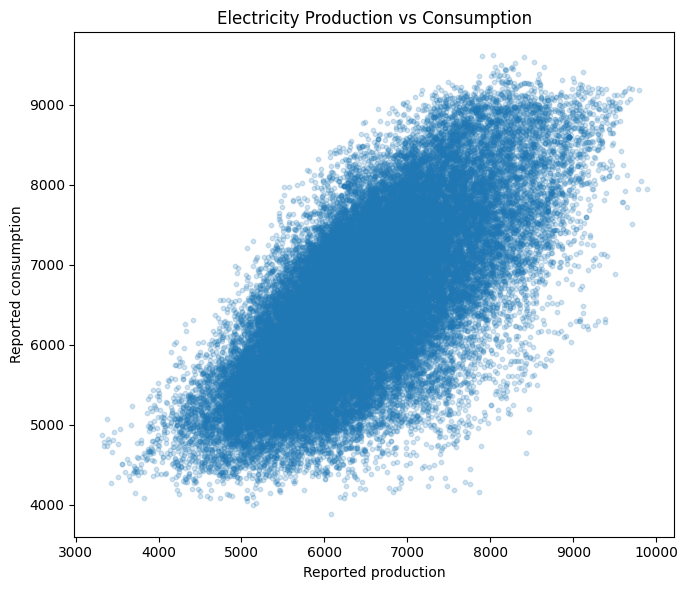

In [16]:
if "Production" not in df.columns:
    raise ValueError("The dataset does not contain the expected Production column.")

pc = df[["DateTime", "Consumption", "Production"]].dropna().copy()
production_consumption_corr = pc["Consumption"].corr(pc["Production"])
pc["Production_minus_Consumption"] = pc["Production"] - pc["Consumption"]

print(f"Correlation between consumption and production: {production_consumption_corr:.4f}")
print("\nProduction minus consumption summary:")
display(pc["Production_minus_Consumption"].describe().to_frame().T)

plt.figure(figsize=(7, 6))
plt.scatter(pc["Production"], pc["Consumption"], alpha=0.2, s=10)
plt.title("Electricity Production vs Consumption")
plt.xlabel("Reported production")
plt.ylabel("Reported consumption")
plt.tight_layout()
plt.show()

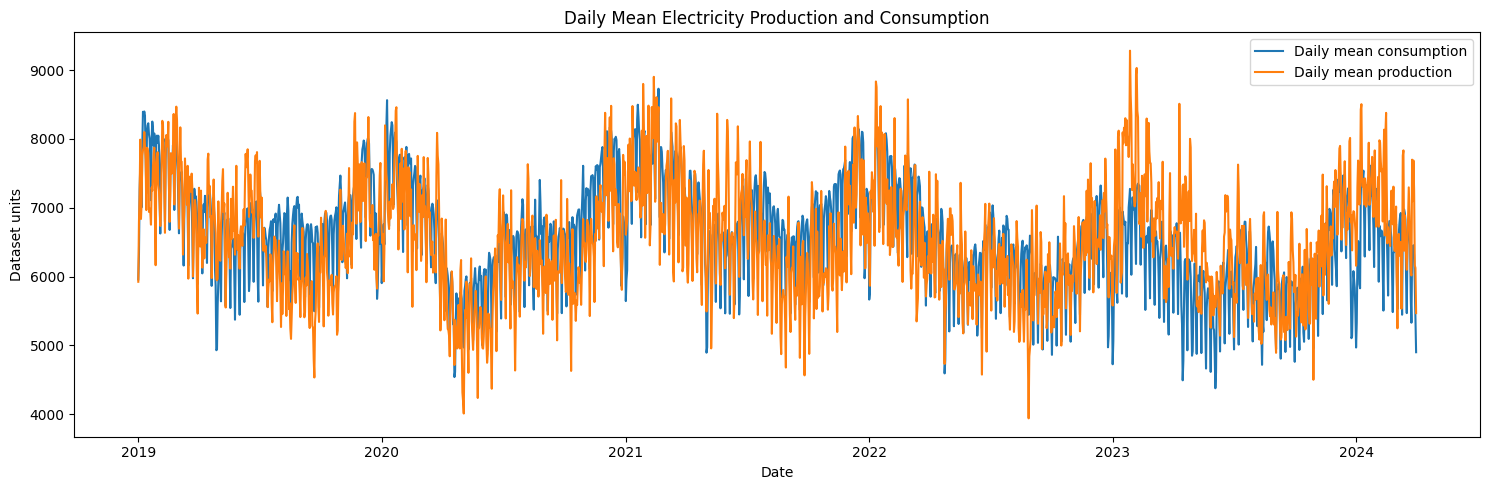

In [17]:
daily_pc = pc.set_index("DateTime")[["Production", "Consumption"]].resample("D").mean()
plt.figure(figsize=(15, 5))
plt.plot(daily_pc.index, daily_pc["Consumption"], label="Daily mean consumption")
plt.plot(daily_pc.index, daily_pc["Production"], label="Daily mean production")
plt.title("Daily Mean Electricity Production and Consumption")
plt.xlabel("Date")
plt.ylabel("Dataset units")
plt.legend()
plt.tight_layout()
plt.show()

##Interpretation

The results show a positive relationship between electricity production and consumption, with a correlation of **0.6951**. The scatter plot shows that higher production is generally associated with higher consumption, although the points are more widely spread than in the lagged-consumption plot. This indicates that the relationship is positive but not perfect. The daily mean time-series plot also shows that production and consumption often move in similar directions, although their levels sometimes differ.

The difference between production and consumption has a mean of approximately −68.97 units and a median of −132 units. This indicates that the recorded production is slightly lower than consumption on average, although the difference varies considerably over time. The middle 50% of the differences range from −641 to 455 units, while the full range extends from −2,459 to 3,789 units. These variations suggest that production does not always match consumption at each recorded observation. However, the results describe an association and a difference between the recorded totals; they do not establish why the differences occur or prove that production directly causes changes in consumption.

## 14. Energy-generation mix

### Additional analytical question
**How do the recorded generation sources compare over time?**

This is an additional question beyond the minimum five. We compare the available source columns to explore whether their typical levels and patterns differ. Confirm the dataset documentation before treating the columns as directly additive components of total production.

,count,mean,std,min,25%,50%,75%,max
Nuclear,"46,011.00","1,291.18",236.55,562.00,"1,347.00","1,383.00","1,405.00","1,457.00"
Wind,"46,011.00",792.31,675.81,-26.00,236.00,592.00,"1,205.00","2,811.00"
Hydroelectric,"46,011.00","1,857.05",692.59,175.00,"1,347.00","1,747.00","2,265.00","4,434.00"
Oil and Gas,"46,011.00","1,171.89",434.75,198.00,858.00,"1,211.00","1,511.00","2,141.00"
Coal,"46,011.00","1,193.16",320.45,279.00,962.00,"1,172.00","1,406.00","2,537.00"
Solar,"46,011.00",156.69,229.50,0.00,0.00,2.00,280.00,"1,137.00"
Biomass,"46,011.00",55.85,14.24,17.00,45.00,57.00,67.00,89.00


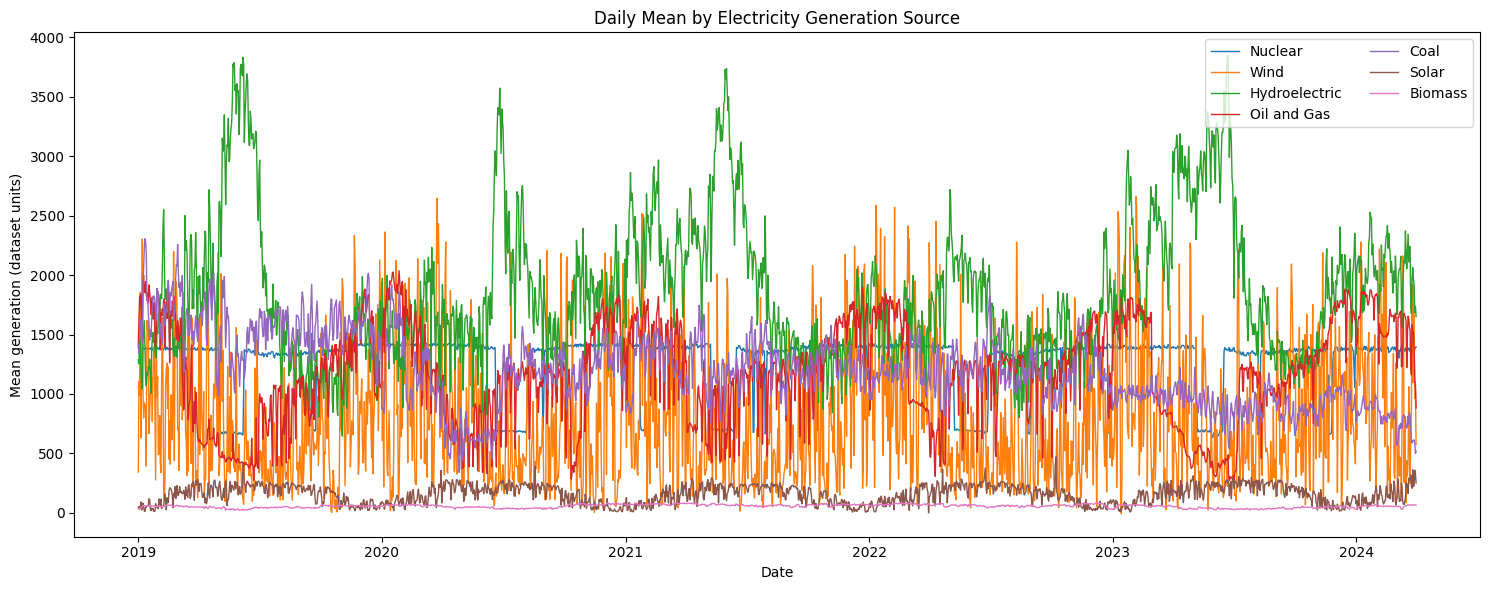

In [18]:
generation_candidates = [
    "Nuclear", "Wind", "Hydroelectric", "Oil and Gas", "Coal", "Solar", "Biomass"
]
generation_cols = [col for col in generation_candidates if col in df.columns]

if generation_cols:
    display(df[generation_cols].describe().T)

    daily_generation = (
        df.set_index("DateTime")[generation_cols]
          .resample("D")
          .mean()
    )

    plt.figure(figsize=(15, 6))
    for col in generation_cols:
        plt.plot(daily_generation.index, daily_generation[col], label=col, linewidth=1)
    plt.title("Daily Mean by Electricity Generation Source")
    plt.xlabel("Date")
    plt.ylabel("Mean generation (dataset units)")
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()
else:
    print("No recognized generation-source columns were found.")

##Interpretation
The numerical distributions show that the different electricity generation sources vary in their typical output and level of variability. Hydroelectric generation has the highest mean among the individual energy sources, at approximately 1,857, followed by nuclear at 1,291, coal at 1,193, and oil and gas at 1,172. Wind generation has a mean of approximately 792, while solar and biomass have much lower means of approximately 157 and 56, respectively.

Wind generation shows substantial variability, with a standard deviation of approximately 676 and values ranging from −26 to 2,811. Its mean is higher than its median of 592, suggesting a right-skewed distribution in which some observations have considerably higher output. Hydroelectric generation also varies considerably, ranging from 175 to 4,434. In comparison, nuclear generation is more concentrated around its median of 1,383, while biomass values are relatively concentrated between the first and third quartiles of 45 and 67.

Solar generation has a particularly uneven distribution. Its median is only 2, its first quartile is zero, and its mean is approximately 157. This indicates that many observations have zero or very low solar output, while some have much higher values. The negative minimum for wind generation should be investigated to understand how it was recorded. Overall, the distributions show that generation sources differ considerably in their output levels and variability, which may be important when analysing the relationship between generation and electricity consumption.



## 15. Correlation overview

This heatmap gives an overview of linear associations among numerical columns. Correlation can help generate hypotheses, but it does not establish causality. Some variables may also be mathematically related (for example, totals and their components), so interpret correlations cautiously.

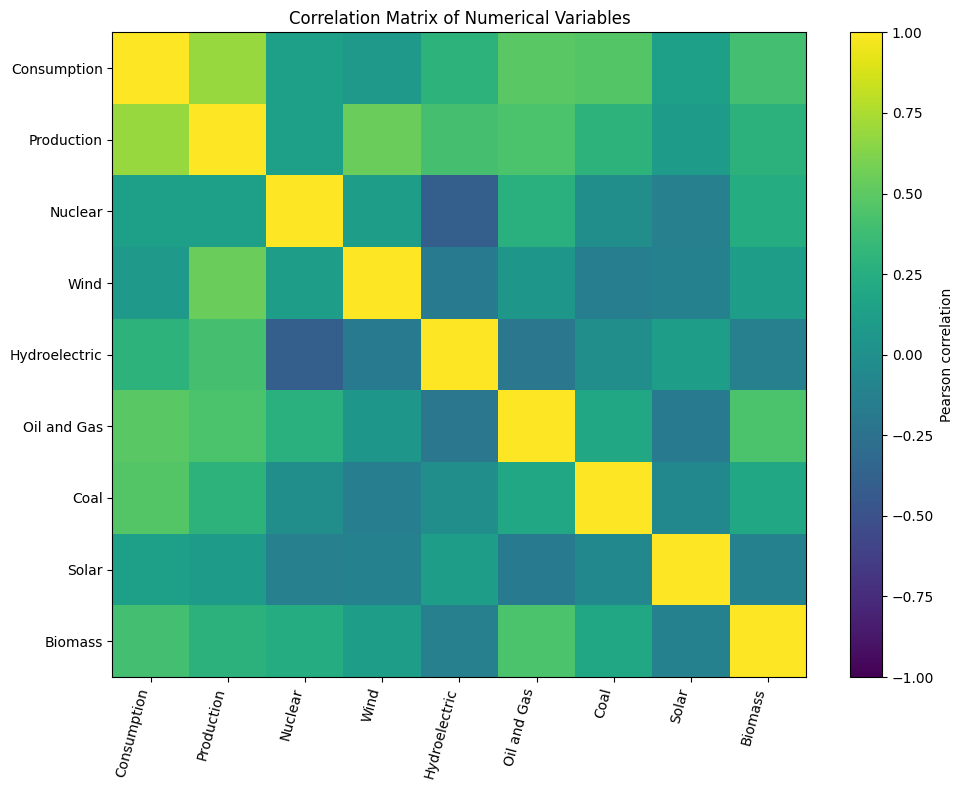

,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
Consumption,1.00,0.70,0.13,0.08,0.29,0.49,0.46,0.13,0.40
Production,0.70,1.00,0.13,0.54,0.41,0.43,0.29,0.10,0.28
Nuclear,0.13,0.13,1.00,0.12,-0.40,0.27,-0.01,-0.13,0.24
Wind,0.08,0.54,0.12,1.00,-0.18,0.06,-0.14,-0.12,0.12
Hydroelectric,0.29,0.41,-0.40,-0.18,1.00,-0.20,-0.01,0.12,-0.13
Oil and Gas,0.49,0.43,0.27,0.06,-0.20,1.00,0.20,-0.19,0.43
Coal,0.46,0.29,-0.01,-0.14,-0.01,0.20,1.00,-0.07,0.19
Solar,0.13,0.10,-0.13,-0.12,0.12,-0.19,-0.07,1.00,-0.12
Biomass,0.40,0.28,0.24,0.12,-0.13,0.43,0.19,-0.12,1.00


In [19]:
corr_cols = [col for col in numeric_cols if col in df.columns]
corr = df[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title("Correlation Matrix of Numerical Variables")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

display(corr.round(2))

##Interpretation

The correlation matrix shows the strength and direction of the linear relationships between electricity consumption, total production, and individual generation sources. Electricity consumption has a positive correlation of approximately **0.70 with total production**, indicating that higher production generally occurs alongside higher consumption. Among the individual generation sources, oil and gas has a correlation of approximately 0.49 with consumption, followed by coal at 0.46, biomass at 0.40, and hydroelectric generation at 0.29. Nuclear and solar generation have weaker positive correlations with consumption, both around 0.13, while wind has a correlation of approximately 0.08.

The matrix also shows relationships between the generation sources themselves. Wind generation has a positive correlation of approximately 0.54 with total production, while hydroelectric generation has a correlation of approximately 0.41 with production. Nuclear and hydroelectric generation have a negative correlation of approximately −0.40, indicating that higher values of one tend to be associated with lower values of the other in this dataset. However, this does not establish that one source causes the other to decrease.

Overall, the matrix suggests that total production and consumption tend to move together, but their relationship is not perfect. The individual generation sources have different relationships with consumption and production. These correlations can help identify useful variables for further time-series analysis and forecasting, although correlation alone does not prove causation and may not capture nonlinear relationships.

## 16. Summary of Task 1A and Task 1B

Use the outputs generated by running this notebook to prepare the final report.

### Task 1A — Dataset understanding
Summarize:
- number of rows and columns;
- time range and observed timestamp frequency;
- missing values, exact duplicates, repeated timestamps, and negative values;
- typical values and variability for important numerical columns;
- limitations and justified data-quality decisions.

### Task 1B — Analytical questions
For each question, report the visualization, the main numerical result, the interpretation, and one limitation where relevant. At least two questions must explicitly use lagged features or moving averages.

### Reproducibility checklist
- [ ] Run all cells from top to bottom.
- [ ] Ensure interpretations agree with the newly generated outputs.
- [ ] Keep the raw CSV unchanged.
- [ ] Coordinate the preprocessing assumptions with the group before model training.

## 17. Reproducible preprocessing for downstream modelling

This section creates a **separate derived hourly dataset** and a feature table for the group to review. It does not overwrite `df_raw` or the original CSV.

**Documented assumptions**
1. Invalid timestamps are dropped and exact duplicate rows are removed.
2. If multiple non-identical records share a timestamp, numeric values are averaged to produce one hourly record.
3. Negative values in generation columns are treated as suspicious and converted to missing values; they are not clipped to zero. This is a modelling assumption that should be checked against the dataset documentation.
4. A regular hourly index is created. Only short internal gaps (up to six consecutive hours) are time-interpolated. Longer gaps remain missing.
5. Lag and rolling features use only previous observations, not the current target value.
6. The feature table is split chronologically (70% train, 15% validation, 15% test), not randomly.

For a strict production forecasting system, imputation should be designed to avoid using future observations to fill past gaps. Here, short-gap interpolation is a documented dataset-preparation assumption for this coursework; the group should consider a past-only strategy if required by the model design.

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TARGET = "Consumption"
TIME_COL = "DateTime"
FREQ = "h"
MAX_GAP_HOURS = 6
LAGS = [1, 2, 3, 24, 48, 168]
ROLL_WINDOWS = [24, 168]
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

OUT_DIR = (DATA_PATH.parent / "processed") if "DATA_PATH" in globals() else Path("processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Processed artifacts will be saved to:", OUT_DIR.resolve())

Processed artifacts will be saved to: /content/drive/MyDrive/TimeSeries_Project/processed


In [21]:
# Audit repeated timestamps before choosing the aggregation rule.
tmp = df_raw.copy()
tmp[TIME_COL] = pd.to_datetime(tmp[TIME_COL], errors="coerce")
invalid_timestamp_count = int(tmp[TIME_COL].isna().sum())
tmp = tmp.dropna(subset=[TIME_COL]).sort_values(TIME_COL)

exact_dups = int(tmp.duplicated().sum())
tmp_no_exact = tmp.drop_duplicates()
repeated_rows = tmp_no_exact[tmp_no_exact[TIME_COL].duplicated(keep=False)]

print("Invalid timestamps:", invalid_timestamp_count)
print("Exact duplicate rows:", exact_dups)
print("Rows participating in repeated-timestamp groups:", len(repeated_rows))
print("Distinct repeated timestamps:", repeated_rows[TIME_COL].nunique())

if len(repeated_rows):
    print("Examples of repeated timestamps:")
    display(repeated_rows.head(10))

# Summarize actual negative generation values for the preprocessing log.
numeric_columns = tmp_no_exact.select_dtypes(include="number").columns.tolist()
generation_columns = [c for c in numeric_columns if c not in {TARGET}]
negative_counts = (tmp_no_exact[generation_columns] < 0).sum()
negative_counts = negative_counts[negative_counts > 0]
print("Negative values in generation columns:")
display(negative_counts.rename("negative_count").to_frame())

Invalid timestamps: 0
Exact duplicate rows: 4
Rows participating in repeated-timestamp groups: 10
Distinct repeated timestamps: 5
Examples of repeated timestamps:


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
7178,2019-10-27 03:00:00,5186,4478,1373,77,750,696,1532,0,49
7179,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
15917,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
15915,2020-10-25 03:00:00,5181,5356,1417,1120,1155,566,1034,0,65
24820,2021-10-31 03:00:00,5351,5265,1414,108,961,1314,1411,0,56
24821,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
33557,2022-10-30 03:00:00,4475,5266,1385,485,1375,904,1064,0,52
33558,2022-10-30 03:00:00,4503,5269,1384,544,1289,924,1073,0,52
42294,2023-10-29 03:00:00,4626,4402,1376,136,1076,864,913,0,37
42295,2023-10-29 03:00:00,4607,4412,1376,221,1084,860,833,0,37


Negative values in generation columns:


,negative_count
Wind,499


In [22]:
def _interpolate_only_short_internal_gaps(frame, max_gap_hours):
    """Interpolate internal NaN runs no longer than max_gap_hours."""
    filled = frame.interpolate(method="time", limit_area="inside")
    for col in frame.columns:
        missing = frame[col].isna()
        run_id = (~missing).cumsum()
        run_length = missing.groupby(run_id).transform("sum")
        filled.loc[missing & (run_length > max_gap_hours), col] = np.nan
    return filled


def clean_data(raw_frame, freq=FREQ, max_gap_hours=MAX_GAP_HOURS):
    """Return a derived regular time series and an auditable cleaning report."""
    report = {"rows_raw": int(len(raw_frame))}
    frame = raw_frame.copy()
    frame = frame.loc[:, ~frame.columns.astype(str).str.startswith("Unnamed")]

    frame[TIME_COL] = pd.to_datetime(frame[TIME_COL], errors="coerce")
    report["invalid_timestamps_dropped"] = int(frame[TIME_COL].isna().sum())
    frame = frame.dropna(subset=[TIME_COL]).sort_values(TIME_COL)

    report["exact_duplicate_rows_dropped"] = int(frame.duplicated().sum())
    frame = frame.drop_duplicates()

    numeric_cols = frame.select_dtypes(include="number").columns.tolist()
    generation_cols = [c for c in numeric_cols if c != TARGET]
    negative_counts = (frame[generation_cols] < 0).sum()
    report["negative_generation_values_marked_missing"] = {
        col: int(count) for col, count in negative_counts.items() if count > 0
    }
    for col in generation_cols:
        frame.loc[frame[col] < 0, col] = np.nan

    report["repeated_timestamp_rows_collapsed"] = int(frame[TIME_COL].duplicated().sum())
    # Average numeric measurements for remaining repeated timestamps.
    frame = frame.groupby(TIME_COL)[numeric_cols].mean().sort_index()

    if frame.empty:
        raise ValueError("No valid timestamped rows remain after parsing.")

    full_index = pd.date_range(frame.index.min(), frame.index.max(), freq=freq, name=TIME_COL)
    report["missing_hourly_timestamps_inserted"] = int(len(full_index.difference(frame.index)))
    frame = frame.reindex(full_index)

    report["missing_values_before_imputation"] = {
        col: int(count) for col, count in frame.isna().sum().items() if count > 0
    }
    frame = _interpolate_only_short_internal_gaps(frame, max_gap_hours)
    report["missing_values_after_short_gap_imputation"] = {
        col: int(count) for col, count in frame.isna().sum().items() if count > 0
    }
    report["rows_after_hourly_regularization"] = int(len(frame))
    report["start"] = str(frame.index.min())
    report["end"] = str(frame.index.max())
    report["frequency"] = freq
    return frame, report


df_clean, clean_report = clean_data(df_raw)
display(pd.Series(clean_report, name="value").to_frame())

,value
rows_raw,46011
invalid_timestamps_dropped,0
exact_duplicate_rows_dropped,4
negative_generation_values_marked_missing,{'Wind': 499}
repeated_timestamp_rows_collapsed,5
missing_hourly_timestamps_inserted,6
missing_values_before_imputation,"{'Consumption': 6, 'Production': 6, 'Nuclear':..."
missing_values_after_short_gap_imputation,{'Wind': 151}
rows_after_hourly_regularization,46008
start,2019-01-01 00:00:00


Unique time differences after regularization: <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[ns]
Duplicate timestamps remaining: 0
Negative values remaining (excluding missing values): 0

Missing values remaining per column:


,missing_count
Consumption,0
Production,0
Nuclear,0
Wind,151
Hydroelectric,0
Oil and Gas,0
Coal,0
Solar,0
Biomass,0


Rows where target 'Consumption' is still missing: 0


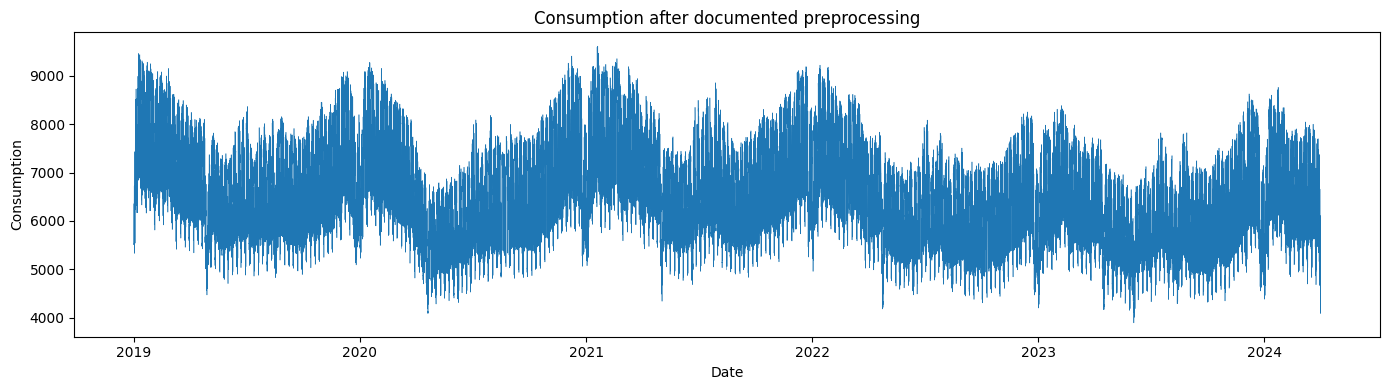

Saved cleaned dataset to: /content/drive/MyDrive/TimeSeries_Project/processed/Electricity_cleaned.csv


In [23]:
# Verify the derived hourly data and visualize its target.
diffs = df_clean.index.to_series().diff().dropna()
print("Unique time differences after regularization:", diffs.unique())
print("Duplicate timestamps remaining:", int(df_clean.index.duplicated().sum()))
print("Negative values remaining (excluding missing values):", int((df_clean.select_dtypes(include="number") < 0).sum().sum()))
print("\nMissing values remaining per column:")
display(df_clean.isna().sum().to_frame("missing_count"))

still_missing_target = df_clean[df_clean[TARGET].isna()]
print(f"Rows where target {TARGET!r} is still missing:", len(still_missing_target))
if len(still_missing_target):
    display(still_missing_target.head(10))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_clean.index, df_clean[TARGET], linewidth=0.4)
ax.set_title("Consumption after documented preprocessing")
ax.set_xlabel("Date")
ax.set_ylabel("Consumption")
plt.tight_layout()
plt.show()

# Save a separate cleaned dataset. The raw CSV is never overwritten.
clean_csv_path = OUT_DIR / "Electricity_cleaned.csv"
df_clean.reset_index().to_csv(clean_csv_path, index=False)
print("Saved cleaned dataset to:", clean_csv_path.resolve())

In [24]:
def add_features(hourly_frame, drop_na=True):
    """Create leakage-aware lag, rolling, and calendar features."""
    out = pd.DataFrame(index=hourly_frame.index)
    out[TARGET] = hourly_frame[TARGET]

    for lag in LAGS:
        out[f"{TARGET}_lag_{lag}"] = hourly_frame[TARGET].shift(lag)

    # Shift first so the rolling features exclude the target at the current timestamp.
    past_target = hourly_frame[TARGET].shift(1)
    for window in ROLL_WINDOWS:
        out[f"{TARGET}_ma_{window}"] = past_target.rolling(window, min_periods=window).mean()
        out[f"{TARGET}_std_{window}"] = past_target.rolling(window, min_periods=window).std()

    for col in [col for col in hourly_frame.columns if col != TARGET]:
        out[f"{col}_lag_1"] = hourly_frame[col].shift(1)

    index = hourly_frame.index
    out["hour"] = index.hour
    out["dayofweek"] = index.dayofweek
    out["month"] = index.month
    out["is_weekend"] = (index.dayofweek >= 5).astype(int)
    out["hour_sin"] = np.sin(2 * np.pi * index.hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * index.hour / 24)
    out["dow_sin"] = np.sin(2 * np.pi * index.dayofweek / 7)
    out["dow_cos"] = np.cos(2 * np.pi * index.dayofweek / 7)
    out["month_sin"] = np.sin(2 * np.pi * (index.month - 1) / 12)
    out["month_cos"] = np.cos(2 * np.pi * (index.month - 1) / 12)

    return out.dropna() if drop_na else out


features_all = add_features(df_clean, drop_na=False)
features = features_all.dropna()
print(f"Rows before dropping incomplete features: {len(features_all):,}")
print(f"Rows after dropping incomplete features: {len(features):,}")
print(f"Rows excluded because of lag warm-up or unresolved gaps: {len(features_all) - len(features):,}")
print(f"Number of predictors: {features.shape[1] - 1}")
display(features.head())

Rows before dropping incomplete features: 46,008
Rows after dropping incomplete features: 45,689
Rows excluded because of lag warm-up or unresolved gaps: 319
Number of predictors: 28


,Consumption,Consumption_lag_1,Consumption_lag_2,Consumption_lag_3,Consumption_lag_24,Consumption_lag_48,Consumption_lag_168,Consumption_ma_24,Consumption_std_24,Consumption_ma_168,Consumption_std_168,Production_lag_1,Nuclear_lag_1,Wind_lag_1,Hydroelectric_lag_1,Oil and Gas_lag_1,Coal_lag_1,Solar_lag_1,Biomass_lag_1,hour,dayofweek,month,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
DateTime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-01-08 00:00:00,"7,106.00","7,369.00","7,859.00","8,501.00","6,512.00","6,665.00","6,352.00","7,883.08","1,027.41","7,062.51","1,011.36","7,331.00","1,386.00","2,200.00",731.00,"1,512.00","1,448.00",0.00,54.00,0,1,1,0,0.00,1.00,0.78,0.62,0.00,1.00
2019-01-08 01:00:00,"6,951.00","7,106.00","7,369.00","7,859.00","6,270.00","6,441.00","6,116.00","7,907.83",999.73,"7,067.00","1,009.86","7,352.00","1,384.00","1,988.00",976.00,"1,524.00","1,427.00",0.00,53.00,1,1,1,0,0.26,0.97,0.78,0.62,0.00,1.00
2019-01-08 02:00:00,"6,890.00","6,951.00","7,106.00","7,369.00","6,172.00","6,297.00","5,873.00","7,936.21",960.10,"7,071.97","1,007.20","7,593.00","1,387.00","1,987.00",907.00,"1,716.00","1,540.00",0.00,55.00,2,1,1,0,0.50,0.87,0.78,0.62,0.00,1.00
2019-01-08 03:00:00,"6,839.00","6,890.00","6,951.00","7,106.00","6,228.00","6,168.00","5,682.00","7,966.12",912.76,"7,078.02","1,003.00","7,726.00","1,392.00","1,848.00",851.00,"1,866.00","1,710.00",0.00,57.00,3,1,1,0,0.71,0.71,0.78,0.62,0.00,1.00
2019-01-08 04:00:00,"6,890.00","6,839.00","6,890.00","6,951.00","6,280.00","6,260.00","5,557.00","7,991.58",869.67,"7,084.91",997.31,"7,602.00","1,393.00","1,573.00",902.00,"1,856.00","1,820.00",0.00,57.00,4,1,1,0,0.87,0.50,0.78,0.62,0.00,1.00


In [25]:
# Sanity-check that lag and rolling features use only prior timestamps.
if len(features):
    timestamp = features.index[len(features) // 2]
    row = features.loc[timestamp]
    history = df_clean[TARGET]

    for lag in LAGS:
        expected_time = timestamp - pd.Timedelta(hours=lag)
        assert expected_time in history.index
        assert np.isclose(row[f"{TARGET}_lag_{lag}"], history.loc[expected_time])

    for window in ROLL_WINDOWS:
        window_start = timestamp - pd.Timedelta(hours=window)
        window_end = timestamp - pd.Timedelta(hours=1)
        expected_window = history.loc[window_start:window_end]
        assert len(expected_window) == window
        assert np.isclose(row[f"{TARGET}_ma_{window}"], expected_window.mean())

    print(f"Feature leakage sanity checks passed for {timestamp}.")
    print(f"Target at t: {row[TARGET]:,.1f}")
    print(f"Consumption lag 1 hour: {row[f'{TARGET}_lag_1']:,.1f}")
    print(f"Consumption lag 24 hours: {row[f'{TARGET}_lag_24']:,.1f}")
else:
    print("No complete feature rows remain; review unresolved gaps before modelling.")

Feature leakage sanity checks passed for 2021-08-21 00:00:00.
Target at t: 5,800.0
Consumption lag 1 hour: 6,247.0
Consumption lag 24 hours: 5,851.0


## 18. Chronological split for downstream modelling

This split is provided as a reproducible handoff for the group. It does not train a model yet. The model-training member should use the same split and feature definitions, or document any agreed changes.

,rows,start,end
train,31982,2019-01-08 00:00:00,2022-09-05 17:00:00
validation,6853,2022-09-05 18:00:00,2023-06-20 09:00:00
test,6854,2023-06-20 10:00:00,2024-03-31 23:00:00


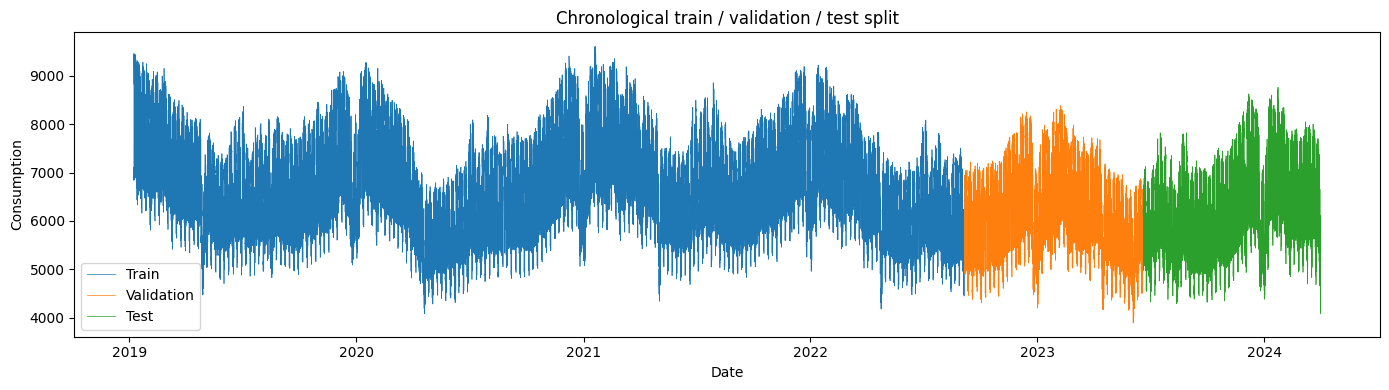

X_train: (31982, 28) | X_val: (6853, 28) | X_test: (6854, 28)
Saved feature table to: /content/drive/MyDrive/TimeSeries_Project/processed/Electricity_features.csv


In [26]:
def _chronological_split(frame, train_fraction=TRAIN_FRAC, validation_fraction=VAL_FRAC):
    n_rows = len(frame)
    train_end = int(n_rows * train_fraction)
    validation_end = int(n_rows * (train_fraction + validation_fraction))
    return frame.iloc[:train_end], frame.iloc[train_end:validation_end], frame.iloc[validation_end:]


train, validation, test = _chronological_split(features)
split_summary = pd.DataFrame({
    "rows": [len(train), len(validation), len(test)],
    "start": [train.index.min() if len(train) else pd.NaT,
              validation.index.min() if len(validation) else pd.NaT,
              test.index.min() if len(test) else pd.NaT],
    "end": [train.index.max() if len(train) else pd.NaT,
            validation.index.max() if len(validation) else pd.NaT,
            test.index.max() if len(test) else pd.NaT],
}, index=["train", "validation", "test"])
display(split_summary)

if len(train) and len(validation) and len(test):
    assert train.index.max() < validation.index.min()
    assert validation.index.max() < test.index.min()

    fig, ax = plt.subplots(figsize=(14, 4))
    for part, label in [(train, "Train"), (validation, "Validation"), (test, "Test")]:
        ax.plot(part.index, part[TARGET], linewidth=0.5, label=label)
    ax.set_title("Chronological train / validation / test split")
    ax.set_xlabel("Date")
    ax.set_ylabel("Consumption")
    ax.legend()
    plt.tight_layout()
    plt.show()

    X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
    X_val, y_val = validation.drop(columns=[TARGET]), validation[TARGET]
    X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]
    print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
else:
    print("Not enough complete rows for a three-way split; review data gaps.")

# Save the modelling feature table for the group.
features_path = OUT_DIR / "Electricity_features.csv"
features.reset_index().to_csv(features_path, index=False)
print("Saved feature table to:", features_path.resolve())

### Handoff notes

- `Electricity.csv` is the raw source and should remain unchanged.
- `Electricity_cleaned.csv` is the derived hourly dataset after documented cleaning.
- `Electricity_features.csv` contains the target, lag/rolling features, and calendar features.
- The model-training member should confirm the cleaning assumptions and use a chronological split to respect time order.
- If a model requires scaling or encoding, fit those transformations on the training data only, then apply them to validation/test data.

In [27]:
from pathlib import Path
import pandas as pd
import numpy as np

# Use the same output folder as your preprocessing notebook
print("Processed folder:", OUT_DIR.resolve())

clean_path = OUT_DIR / "Electricity_cleaned.csv"
features_path = OUT_DIR / "Electricity_features.csv"

# 1. Confirm that both files exist
for path in [clean_path, features_path]:
    print(f"{path.name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

if not clean_path.exists() or not features_path.exists():
    raise FileNotFoundError(
        "One or both files are missing. Rerun the preprocessing cells first."
    )

# 2. Load the saved files
clean_df = pd.read_csv(clean_path, parse_dates=["DateTime"])
features_df = pd.read_csv(features_path, parse_dates=["DateTime"])

# 3. Inspect their dimensions
print("\nCLEANED DATASET")
print("Shape:", clean_df.shape)
print("Date range:", clean_df["DateTime"].min(), "to", clean_df["DateTime"].max())
print("Duplicate timestamps:", clean_df["DateTime"].duplicated().sum())
print("Missing values:", int(clean_df.isna().sum().sum()))

print("\nFEATURE DATASET")
print("Shape:", features_df.shape)
print("Date range:", features_df["DateTime"].min(), "to", features_df["DateTime"].max())
print("Duplicate timestamps:", features_df["DateTime"].duplicated().sum())
print("Missing values:", int(features_df.isna().sum().sum()))

# 4. Check the target and expected time-series features
required_columns = [
    "Consumption",
    "Consumption_lag_1",
    "Consumption_lag_24",
    "Consumption_ma_24",
    "Consumption_ma_168",
    "hour",
    "dayofweek",
    "month"
]

print("\nFEATURE CHECK")
for col in required_columns:
    print(f"{col}: {'OK' if col in features_df.columns else 'MISSING'}")

# 5. Verify that feature timestamps are in chronological order
print(
    "\nFeature timestamps sorted:",
    features_df["DateTime"].is_monotonic_increasing
)

display(features_df.head())
display(features_df.tail())

Processed folder: /content/drive/MyDrive/TimeSeries_Project/processed
Electricity_cleaned.csv: FOUND
Electricity_features.csv: FOUND

CLEANED DATASET
Shape: (46008, 10)
Date range: 2019-01-01 00:00:00 to 2024-03-31 23:00:00
Duplicate timestamps: 0
Missing values: 151

FEATURE DATASET
Shape: (45689, 30)
Date range: 2019-01-08 00:00:00 to 2024-03-31 23:00:00
Duplicate timestamps: 0
Missing values: 0

FEATURE CHECK
Consumption: OK
Consumption_lag_1: OK
Consumption_lag_24: OK
Consumption_ma_24: OK
Consumption_ma_168: OK
hour: OK
dayofweek: OK
month: OK

Feature timestamps sorted: True


,DateTime,Consumption,Consumption_lag_1,Consumption_lag_2,Consumption_lag_3,Consumption_lag_24,Consumption_lag_48,Consumption_lag_168,Consumption_ma_24,Consumption_std_24,Consumption_ma_168,Consumption_std_168,Production_lag_1,Nuclear_lag_1,Wind_lag_1,Hydroelectric_lag_1,Oil and Gas_lag_1,Coal_lag_1,Solar_lag_1,Biomass_lag_1,hour,dayofweek,month,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
0,2019-01-08 00:00:00,"7,106.00","7,369.00","7,859.00","8,501.00","6,512.00","6,665.00","6,352.00","7,883.08","1,027.41","7,062.51","1,011.36","7,331.00","1,386.00","2,200.00",731.00,"1,512.00","1,448.00",0.00,54.00,0,1,1,0,0.00,1.00,0.78,0.62,0.00,1.00
1,2019-01-08 01:00:00,"6,951.00","7,106.00","7,369.00","7,859.00","6,270.00","6,441.00","6,116.00","7,907.83",999.73,"7,067.00","1,009.86","7,352.00","1,384.00","1,988.00",976.00,"1,524.00","1,427.00",0.00,53.00,1,1,1,0,0.26,0.97,0.78,0.62,0.00,1.00
2,2019-01-08 02:00:00,"6,890.00","6,951.00","7,106.00","7,369.00","6,172.00","6,297.00","5,873.00","7,936.21",960.10,"7,071.97","1,007.20","7,593.00","1,387.00","1,987.00",907.00,"1,716.00","1,540.00",0.00,55.00,2,1,1,0,0.50,0.87,0.78,0.62,0.00,1.00
3,2019-01-08 03:00:00,"6,839.00","6,890.00","6,951.00","7,106.00","6,228.00","6,168.00","5,682.00","7,966.12",912.76,"7,078.02","1,003.00","7,726.00","1,392.00","1,848.00",851.00,"1,866.00","1,710.00",0.00,57.00,3,1,1,0,0.71,0.71,0.78,0.62,0.00,1.00
4,2019-01-08 04:00:00,"6,890.00","6,839.00","6,890.00","6,951.00","6,280.00","6,260.00","5,557.00","7,991.58",869.67,"7,084.91",997.31,"7,602.00","1,393.00","1,573.00",902.00,"1,856.00","1,820.00",0.00,57.00,4,1,1,0,0.87,0.50,0.78,0.62,0.00,1.00


,DateTime,Consumption,Consumption_lag_1,Consumption_lag_2,Consumption_lag_3,Consumption_lag_24,Consumption_lag_48,Consumption_lag_168,Consumption_ma_24,Consumption_std_24,Consumption_ma_168,Consumption_std_168,Production_lag_1,Nuclear_lag_1,Wind_lag_1,Hydroelectric_lag_1,Oil and Gas_lag_1,Coal_lag_1,Solar_lag_1,Biomass_lag_1,hour,dayofweek,month,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
45684,2024-03-31 19:00:00,"5,618.00","5,424.00","5,172.00","4,859.00","6,657.00","7,372.00","6,594.00","4,983.44",697.03,"5,952.50",843.48,"6,228.00","1,395.00",555.00,"2,219.00",918.00,548.00,47.00,65.00,19,6,3,1,-0.97,0.26,-0.78,0.62,0.87,0.50
45685,2024-03-31 20:00:00,"6,107.00","5,618.00","5,424.00","5,172.00","6,561.00","7,226.00","6,566.00","4,940.15",616.14,"5,946.69",842.40,"5,902.00","1,398.00",505.00,"2,294.00","1,012.00",620.00,6.00,65.00,20,6,3,1,-0.87,0.50,-0.78,0.62,0.87,0.50
45686,2024-03-31 21:00:00,"5,991.00","6,107.00","5,618.00","5,424.00","6,290.00","6,970.00","6,366.00","4,921.23",569.42,"5,943.96",841.12,"6,205.00","1,395.00",671.00,"2,389.00","1,037.00",645.00,0.00,66.00,21,6,3,1,-0.71,0.71,-0.78,0.62,0.87,0.50
45687,2024-03-31 22:00:00,"5,527.00","5,991.00","6,107.00","5,618.00","5,738.00","6,326.00","5,947.00","4,908.77",540.71,"5,941.73",840.49,"5,855.00","1,395.00",868.00,"2,201.00",705.00,621.00,0.00,66.00,22,6,3,1,-0.50,0.87,-0.78,0.62,0.87,0.50
45688,2024-03-31 23:00:00,"5,111.00","5,527.00","5,991.00","6,107.00","5,323.00","5,814.00","5,547.00","4,899.98",528.21,"5,939.23",841.10,"5,726.00","1,393.00",908.00,"2,088.00",648.00,622.00,0.00,66.00,23,6,3,1,-0.26,0.97,-0.78,0.62,0.87,0.50
